# 08C — f04 padding through the frozen detector

## Objective

Notebook 08B established that `f04`'s low segmentation-coverage recall is largely an **endpoint
truncation** problem:

- `0 ms` padding: about 80% of calls reach the 50%-coverage criterion;
- `10 ms` per side: about 96%;
- `20 ms` per side: 100%.

That does **not** automatically mean 20 ms is best for the complete system.

The classifier does not see a binary "covered/not covered" flag. It sees the actual candidate waveform.
Adding context around a candidate can:

- help by restoring missing call structure;
- hurt by adding noise or competing vocalizations;
- merge nearby candidates;
- change PLP-RASTA frame statistics and therefore GMM scores.

This notebook therefore compares only:

`f04 padding ∈ {0, 10, 20} ms`

through the **already frozen final detector**:

**original unfiltered candidate waveform → 20 PLP-RASTA → frozen GMMs → winning hypothesis → final LLR
threshold → accepted/rejected**

No pond audio is used. No GMM, LLR threshold, `C`, FIR band, or endpoint logic is changed.

---

## Important provenance

`[PAPER]`

The paper uses the band-filtered signal only for endpoint detection, then extracts features from the
corresponding interval of the **original unfiltered recording**.

`[PROJECT EXTENSION]`

Symmetric post-segmentation padding is **not described in the paper**. This experiment exists only
because our recovered Dataset-1 implementation showed systematic endpoint truncation for `f04`.

If padding is adopted, it must remain explicitly documented as a project-specific segmentation
correction.

In [1]:
from pathlib import Path
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from scipy.io import loadmat
from scipy.linalg import solve_toeplitz
from scipy.signal import lfilter

try:
    from dotenv import load_dotenv
except ImportError as exc:
    raise ImportError(
        "Notebook 08C needs python-dotenv to resolve MENDELEY_CALL_DIR."
    ) from exc

pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 250)
pd.set_option("display.max_columns", 140)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = (
    REPO_ROOT / "data" / "processed"
)

SEGMENTATION_DIR = (
    PROCESSED_DIR
    / "candidate_call_segmentation"
)

PADDING_DIAGNOSTIC_DIR = (
    SEGMENTATION_DIR
    / "endpoint_padding_diagnostic"
)

RESULTS_DIR = (
    SEGMENTATION_DIR
    / "f04_padding_end_to_end"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODEL_DIR = (
    REPO_ROOT
    / "models"
    / "gmm_robust_final"
)

CALLS_PATH = (
    PROCESSED_DIR / "calls.csv"
)

CANDIDATES_PATH = (
    SEGMENTATION_DIR
    / "selected_dataset1_candidates.csv"
)

SEGMENTATION_CONFIG_PATH = (
    SEGMENTATION_DIR
    / "selected_segmentation_configuration.json"
)

PADDING_SUMMARY_PATH = (
    PADDING_DIAGNOSTIC_DIR
    / "padding_sweep_by_species.csv"
)

MANIFEST_PATH = (
    MODEL_DIR
    / "final_detector_manifest.json"
)

THRESHOLDS_PATH = (
    MODEL_DIR
    / "thresholds.json"
)

METADATA_PATH = (
    MODEL_DIR
    / "detector_metadata.json"
)

for path in (
    CALLS_PATH,
    CANDIDATES_PATH,
    SEGMENTATION_CONFIG_PATH,
    PADDING_SUMMARY_PATH,
    MANIFEST_PATH,
    THRESHOLDS_PATH,
    METADATA_PATH,
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required input: {path}"
        )

load_dotenv(
    REPO_ROOT / ".env"
)

mendeley_value = os.environ.get(
    "MENDELEY_CALL_DIR"
)

if not mendeley_value:
    raise RuntimeError(
        "MENDELEY_CALL_DIR is not defined in .env."
    )

MENDELEY_CALL_DIR = Path(
    mendeley_value
).expanduser()

if not MENDELEY_CALL_DIR.is_dir():
    raise FileNotFoundError(
        f"MENDELEY_CALL_DIR does not exist: {MENDELEY_CALL_DIR}"
    )

print("Repository root :", REPO_ROOT)
print("Frozen models   :", MODEL_DIR)
print("Dataset 1       :", MENDELEY_CALL_DIR)
print("08C outputs     :", RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Frozen models   : C:\Users\sofia\Projects\PUCE\frog-presence-replication\models\gmm_robust_final
Dataset 1       : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data
08C outputs     : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\candidate_call_segmentation\f04_padding_end_to_end


## 2. Verify frozen detector provenance

This notebook must use the exact detector frozen by 07D.

In [2]:
with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8",
) as f:
    manifest = json.load(f)

with open(
    THRESHOLDS_PATH,
    "r",
    encoding="utf-8",
) as f:
    thresholds = json.load(f)

with open(
    METADATA_PATH,
    "r",
    encoding="utf-8",
) as f:
    detector_metadata = json.load(f)

with open(
    SEGMENTATION_CONFIG_PATH,
    "r",
    encoding="utf-8",
) as f:
    segmentation_config = json.load(f)

CLASSES = tuple(
    manifest[
        "classes"
    ]
)

if manifest[
    "feature"
] != "20_PLP_RASTA":
    raise RuntimeError(
        "08C expects the frozen feature to be 20_PLP_RASTA."
    )

if int(
    manifest[
        "n_components"
    ]
) != 4:
    raise RuntimeError(
        "08C expects the frozen final GMM order M=4."
    )

if "f04" not in CLASSES:
    raise RuntimeError(
        "f04 is not present in the frozen detector."
    )

if set(
    thresholds
) != set(
    CLASSES
):
    raise RuntimeError(
        "Threshold classes do not match final detector classes."
    )

PADDING_MS_GRID = (
    0,
    10,
    20,
)

TARGET_CODE = "f04"

CALL_COVERAGE_TARGET = 0.50

print("Detector status :", manifest["detector_status"])
print("Feature         :", manifest["feature"])
print("GMM order       :", manifest["n_components"])
print("Classes         :", CLASSES)
print("f04 threshold   :", thresholds[TARGET_CODE])
print("Padding grid    :", PADDING_MS_GRID)

Detector status : frozen_after_07C_threshold_promotion
Feature         : 20_PLP_RASTA
GMM order       : 4
Classes         : ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')
f04 threshold   : 5.064719360802286
Padding grid    : (0, 10, 20)


## 3. Load frozen GMMs

No model fitting occurs here.

In [3]:
MODELS = {}

for code_name in CLASSES:

    model_path = (
        MODEL_DIR
        / f"{code_name}.joblib"
    )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Missing frozen GMM: {model_path}"
        )

    MODELS[
        code_name
    ] = joblib.load(
        model_path
    )

print(
    "Loaded frozen GMMs:",
    sorted(
        MODELS
    ),
)

for code_name, model in MODELS.items():
    print(
        f"{code_name}: "
        f"components={model.n_components}, "
        f"covariance={model.covariance_type}"
    )

Loaded frozen GMMs: ['f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10']
f01: components=4, covariance=diag
f02: components=4, covariance=diag
f03: components=4, covariance=diag
f04: components=4, covariance=diag
f05: components=4, covariance=diag
f06: components=4, covariance=diag
f07: components=4, covariance=diag
f08: components=4, covariance=diag
f10: components=4, covariance=diag


## 4. Reconstruct exact Dataset-1 call endpoints

As before, `calls.csv` is not modified. The `.mat` annotations are reconstructed in memory and aligned
row-by-row.

In [4]:
calls = (
    pd.read_csv(
        CALLS_PATH
    )
    .copy()
    .reset_index(drop=True)
)

calls[
    "call_id"
] = [
    f"call_{i:04d}"
    for i
    in range(
        len(calls)
    )
]

SEGMENT_DIR = (
    MENDELEY_CALL_DIR
    / "segment files"
)

PAPER_TABLE1 = pd.DataFrame(
    [
        ("f01", "Boana alfaroi", "cantos_alfaroi.mat"),
        ("f02", "Dendropsophus bifurcus", "cantos_bifurcus.mat"),
        ("f03", "Boana cinerascens", "cantos_cinerascens.mat"),
        ("f04", "Pristimantis conspicillatus", "cantos_conspicillatus.mat"),
        ("f05", "Leptodactylus discodactylus", "cantos_discodactylus.mat"),
        ("f06", "Osteocephalus fuscifacies", "cantos_fuscifacies.mat"),
        ("f07", "Boana lanciformis", "cantos_lanciformis.mat"),
        ("f08", "Rhinella margaritifera", "cantos_margaritifer.mat"),
        ("f09", "Dendropsophus parviceps", "cantos_parviceps.mat"),
        ("f10", "Engystomops petersi", "cantos_petersi.mat"),
    ],
    columns=[
        "code",
        "species",
        "segment_file",
    ],
)

WAV_ON_DISK = {
    path.name.lower(): path
    for path
    in MENDELEY_CALL_DIR.rglob("*")
    if path.suffix.lower() == ".wav"
}


def read_segment_file(
    filename,
):
    mat = loadmat(
        SEGMENT_DIR
        / filename
    )

    if "cantos" not in mat:
        raise KeyError(
            f"{filename} does not contain 'cantos'."
        )

    rows = []

    for recording_index, (
        wav_path,
        intervals,
        rate,
    ) in enumerate(
        mat[
            "cantos"
        ]
    ):
        wav = Path(
            str(
                wav_path[0]
            ).replace(
                "\\",
                "/",
            )
        ).name

        sr = int(
            rate[0][0]
        )

        for start, end in intervals:
            rows.append({
                "segment_file":
                    filename,
                "recording":
                    recording_index,
                "wav":
                    wav,
                "rate":
                    sr,
                "start":
                    int(start),
                "end":
                    int(end),
            })

    return pd.DataFrame(
        rows
    )


annotated = pd.concat(
    [
        read_segment_file(
            filename
        )
        for filename
        in PAPER_TABLE1[
            "segment_file"
        ]
    ],
    ignore_index=True,
)

annotated = annotated.merge(
    PAPER_TABLE1,
    on="segment_file",
    how="left",
)

annotated[
    "seconds"
] = (
    annotated[
        "end"
    ]
    - annotated[
        "start"
    ]
) / annotated[
    "rate"
]

annotated[
    "on_disk"
] = (
    annotated[
        "wav"
    ]
    .str.lower()
    .isin(
        WAV_ON_DISK
    )
)

available_annotations = (
    annotated[
        annotated[
            "on_disk"
        ]
    ]
    .reset_index(drop=True)
)

if len(
    available_annotations
) != len(
    calls
):
    raise RuntimeError(
        "Reconstructed annotations and calls.csv have different row counts."
    )

alignment = pd.DataFrame({
    "code":
        calls["code"].astype(str).to_numpy()
        == available_annotations["code"].astype(str).to_numpy(),

    "species":
        calls["species"].astype(str).to_numpy()
        == available_annotations["species"].astype(str).to_numpy(),

    "wav":
        calls["wav"].astype(str).str.lower().to_numpy()
        == available_annotations["wav"].astype(str).str.lower().to_numpy(),

    "recording":
        calls["recording"].astype(int).to_numpy()
        == available_annotations["recording"].astype(int).to_numpy(),

    "rate":
        calls["rate"].astype(int).to_numpy()
        == available_annotations["rate"].astype(int).to_numpy(),

    "seconds":
        np.isclose(
            calls["seconds"].astype(float).to_numpy(),
            available_annotations["seconds"].astype(float).to_numpy(),
            atol=1e-10,
            rtol=1e-10,
        ),
})

display(
    alignment.mean().rename(
        "share_matching"
    ).to_frame()
)

if not alignment.to_numpy().all():
    bad = np.where(
        ~alignment
        .all(axis=1)
        .to_numpy()
    )[0]

    raise RuntimeError(
        f"Endpoint alignment failed for {len(bad)} rows."
    )

calls[
    "start"
] = (
    available_annotations[
        "start"
    ]
    .astype(int)
    .to_numpy()
)

calls[
    "end"
] = (
    available_annotations[
        "end"
    ]
    .astype(int)
    .to_numpy()
)

calls[
    "recording_group"
] = (
    calls[
        "wav"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

calls[
    "resolved_wav"
] = [
    str(
        WAV_ON_DISK[
            wav.lower()
        ]
    )
    for wav
    in calls[
        "wav"
    ]
]

f04_calls = (
    calls[
        calls[
            "code"
        ] == TARGET_CODE
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "f04 annotated calls:",
    len(
        f04_calls
    ),
)

,share_matching
code,1.0
species,1.0
wav,1.0
recording,1.0
rate,1.0
seconds,1.0


f04 annotated calls: 186


## 5. Load the exact f04 candidates selected by notebook 08

These are the candidates generated using the already-selected `f04` segmentation constant.

Only endpoint padding is varied.

In [5]:
all_candidates = pd.read_csv(
    CANDIDATES_PATH
)

f04_candidates = (
    all_candidates[
        all_candidates[
            "code"
        ] == TARGET_CODE
    ]
    .copy()
    .reset_index(drop=True)
)

if f04_candidates.empty:
    raise RuntimeError(
        "Notebook 08 produced no f04 candidates."
    )

selected_C = float(
    segmentation_config[
        "selection"
    ][
        "C_by_code"
    ][
        TARGET_CODE
    ]
)

candidate_C_values = set(
    np.round(
        f04_candidates[
            "C"
        ].astype(float),
        10,
    )
)

if candidate_C_values != {
    round(
        selected_C,
        10,
    )
}:
    raise RuntimeError(
        f"f04 candidate C values {candidate_C_values} "
        f"do not match selected C={selected_C}."
    )

print(
    "f04 selected C       :",
    selected_C,
)

print(
    "Original f04 candidates:",
    len(
        f04_candidates
    ),
)

print(
    "f04 source WAVs       :",
    f04_candidates[
        "recording_group"
    ].nunique(),
)

f04 selected C       : 10.0
Original f04 candidates: 2037
f04 source WAVs       : 9


## 6. Exact 20-dimensional PLP-RASTA frontend used for final model selection

This is the same reconstructed implementation used in notebook 05 when `20_PLP_RASTA` was introduced
and then carried into notebooks 06B and 07.

Settings:

- pre-emphasis: `0.99`;
- frame: `20 ms`;
- overlap: `75%`;
- FFT: `1024`;
- Bark filters: `24`;
- classic RASTA temporal filtering;
- equal-loudness weighting;
- cube-root compression;
- LPC order: `20`;
- output: `20` cepstral coefficients.

The paper does not publish enough numerical PLP detail to claim byte-identical reproduction. The key
requirement here is internal consistency with the feature extractor used to train the frozen GMMs.

In [6]:
PRE_EMPHASIS = 0.99
FRAME_SECONDS = 0.020
OVERLAP = 0.75
NFFT = 1024

N_BARK_FILTERS = 24
PLP_ORDER = 20
N_PLP_CEPSTRA = 20


def pre_emphasise(
    audio,
):
    audio = np.asarray(
        audio,
        dtype=np.float64,
    )

    if len(audio) == 0:
        return audio.copy()

    out = np.empty_like(
        audio
    )

    out[0] = audio[0]

    out[1:] = (
        audio[1:]
        - PRE_EMPHASIS
        * audio[:-1]
    )

    return out


def frame_audio(
    audio,
    sr,
):
    frame_length = int(
        round(
            FRAME_SECONDS
            * sr
        )
    )

    hop_seconds = (
        FRAME_SECONDS
        * (
            1.0
            - OVERLAP
        )
    )

    hop_length = int(
        round(
            hop_seconds
            * sr
        )
    )

    if len(audio) < frame_length:
        return np.empty(
            (
                0,
                frame_length,
            ),
            dtype=float,
        )

    n_frames = (
        1
        + (
            len(audio)
            - frame_length
        )
        // hop_length
    )

    starts = (
        np.arange(
            n_frames
        )
        * hop_length
    )

    return np.stack([
        audio[
            start:
            start
            + frame_length
        ]
        for start
        in starts
    ])


def frame_power_spectrum(
    audio,
    sr,
):
    emphasized = pre_emphasise(
        audio
    )

    frames = frame_audio(
        emphasized,
        sr,
    )

    if len(frames) == 0:
        return (
            np.empty(
                (
                    0,
                    NFFT // 2 + 1,
                )
            ),
            frames,
        )

    window = np.hamming(
        frames.shape[1]
    )

    spectrum = np.fft.rfft(
        frames
        * window[None, :],
        n=NFFT,
        axis=1,
    )

    power = (
        np.abs(
            spectrum
        ) ** 2
    ) / NFFT

    return power, frames


def hz_to_bark(
    hz,
):
    hz = np.asarray(
        hz,
        dtype=float,
    )

    return (
        13.0
        * np.arctan(
            0.00076
            * hz
        )
        + 3.5
        * np.arctan(
            (
                hz
                / 7500.0
            ) ** 2
        )
    )


def bark_to_hz(
    bark,
):
    bark = np.asarray(
        bark,
        dtype=float,
    )

    hz_grid = np.linspace(
        0.0,
        24_000.0,
        200_001,
    )

    bark_grid = hz_to_bark(
        hz_grid
    )

    return np.interp(
        bark,
        bark_grid,
        hz_grid,
    )


_BARK_BANK_CACHE = {}


def bark_filterbank(
    sr,
    n_fft=NFFT,
    n_filters=N_BARK_FILTERS,
):
    cache_key = (
        int(sr),
        int(n_fft),
        int(n_filters),
    )

    if cache_key in _BARK_BANK_CACHE:
        return _BARK_BANK_CACHE[
            cache_key
        ]

    max_hz = sr / 2

    max_bark = float(
        hz_to_bark(
            max_hz
        )
    )

    bark_points = np.linspace(
        0.0,
        max_bark,
        n_filters + 2,
    )

    hz_points = bark_to_hz(
        bark_points
    )

    fft_freqs = np.fft.rfftfreq(
        n_fft,
        d=1.0 / sr,
    )

    bank = np.zeros(
        (
            n_filters,
            len(fft_freqs),
        ),
        dtype=float,
    )

    centers = []

    for i in range(
        n_filters
    ):
        left = hz_points[i]
        center = hz_points[i + 1]
        right = hz_points[i + 2]

        centers.append(
            center
        )

        left_mask = (
            (
                fft_freqs
                >= left
            )
            & (
                fft_freqs
                <= center
            )
        )

        right_mask = (
            (
                fft_freqs
                >= center
            )
            & (
                fft_freqs
                <= right
            )
        )

        if center > left:
            bank[
                i,
                left_mask,
            ] = (
                fft_freqs[
                    left_mask
                ]
                - left
            ) / (
                center
                - left
            )

        if right > center:
            bank[
                i,
                right_mask,
            ] = (
                right
                - fft_freqs[
                    right_mask
                ]
            ) / (
                right
                - center
            )

    result = (
        bank,
        np.asarray(
            centers
        ),
    )

    _BARK_BANK_CACHE[
        cache_key
    ] = result

    return result


def rasta_filter_log_spectrum(
    log_spectrum,
):
    numerator = np.array([
        0.2,
        0.1,
        0.0,
        -0.1,
        -0.2,
    ])

    denominator = np.array([
        1.0,
        -0.94,
    ])

    return lfilter(
        numerator,
        denominator,
        log_spectrum,
        axis=0,
    )


def equal_loudness_curve(
    freq_hz,
):
    f2 = np.asarray(
        freq_hz,
        dtype=float,
    ) ** 2

    numerator = (
        (
            f2
            + 1.6e5
        )
        * (
            f2 ** 2
        )
    )

    denominator = (
        (
            f2
            + 1.44e6
        )
        * (
            (
                f2
                + 9.61e6
            ) ** 2
        )
    )

    curve = (
        numerator
        / np.maximum(
            denominator,
            np.finfo(
                float
            ).eps,
        )
    )

    return np.maximum(
        curve,
        np.finfo(
            float
        ).eps,
    )


def auditory_spectrum_to_lpc(
    spectrum,
    order=PLP_ORDER,
):
    spectrum = np.asarray(
        spectrum,
        dtype=float,
    )

    n_ifft = 2 * (
        len(
            spectrum
        )
        - 1
    )

    autocorr = np.fft.irfft(
        spectrum,
        n=n_ifft,
    )

    autocorr = np.real(
        autocorr[
            :
            order + 1
        ]
    )

    autocorr[0] = max(
        autocorr[0],
        1e-10,
    )

    r0 = autocorr[0]

    autocorr[0] += (
        1e-6
        * abs(
            r0
        )
    )

    try:
        coeff = solve_toeplitz(
            (
                autocorr[
                    :
                    order
                ],
                autocorr[
                    :
                    order
                ],
            ),
            -autocorr[
                1:
                order + 1
            ],
        )

    except Exception:
        coeff = np.zeros(
            order,
            dtype=float,
        )

    lpc = np.concatenate([
        [
            1.0
        ],
        coeff,
    ])

    error = float(
        autocorr[0]
        + np.dot(
            autocorr[
                1:
                order + 1
            ],
            coeff,
        )
    )

    return (
        lpc,
        max(
            error,
            1e-12,
        ),
    )


def lpc_to_cepstra(
    lpc,
    error,
    n_cepstra=N_PLP_CEPSTRA,
):
    order = (
        len(lpc)
        - 1
    )

    c = np.zeros(
        n_cepstra,
        dtype=float,
    )

    c[0] = np.log(
        max(
            error,
            1e-12,
        )
    )

    for n in range(
        1,
        n_cepstra,
    ):
        total = 0.0

        k_start = max(
            1,
            n - order,
        )

        for k in range(
            k_start,
            n,
        ):
            a_index = (
                n
                - k
            )

            if (
                a_index
                <= order
                and k
                < len(c)
            ):
                total += (
                    (
                        k
                        / n
                    )
                    * c[k]
                    * lpc[
                        a_index
                    ]
                )

        if n <= order:
            c[n] = (
                -lpc[n]
                - total
            )
        else:
            c[n] = (
                -total
            )

    return c


def plp_rasta_20(
    audio,
    sr,
):
    power, frames = (
        frame_power_spectrum(
            audio,
            sr,
        )
    )

    if len(frames) == 0:
        return np.empty(
            (
                0,
                N_PLP_CEPSTRA,
            )
        )

    bark_bank, centers_hz = (
        bark_filterbank(
            sr
        )
    )

    critical = (
        power
        @ bark_bank.T
    )

    critical = np.maximum(
        critical,
        np.finfo(
            float
        ).eps,
    )

    log_critical = np.log(
        critical
    )

    rasta_log = (
        rasta_filter_log_spectrum(
            log_critical
        )
    )

    rasta_energy = np.exp(
        rasta_log
    )

    eql = equal_loudness_curve(
        centers_hz
    )

    post_auditory = (
        rasta_energy
        * eql[
            None,
            :
        ]
    )

    compressed = np.cbrt(
        np.maximum(
            post_auditory,
            np.finfo(
                float
            ).eps,
        )
    )

    features_out = []

    for auditory_frame in compressed:

        lpc, error = (
            auditory_spectrum_to_lpc(
                auditory_frame,
                order=PLP_ORDER,
            )
        )

        features_out.append(
            lpc_to_cepstra(
                lpc,
                error,
                n_cepstra=N_PLP_CEPSTRA,
            )
        )

    return np.asarray(
        features_out,
        dtype=float,
    )

## 7. Detector scoring

The whole-candidate score is the GMM's mean frame log-likelihood, matching the project/paper call-level
score definition.

Verification uses the final frozen rule:

\[
LLR_k = s_k - \operatorname{median}_{j
e k}(s_j).
\]

Only the winning hypothesis is verified.

In [7]:
def score_candidate_features(
    X,
):
    X = np.asarray(
        X,
        dtype=float,
    )

    if (
        X.ndim != 2
        or X.shape[1] != 20
        or len(X) == 0
        or not np.isfinite(
            X
        ).all()
    ):
        return None

    scores = {
        code_name:
            float(
                model.score(
                    X
                )
            )
        for code_name, model
        in MODELS.items()
    }

    hypothesis = max(
        scores,
        key=scores.get,
    )

    alternatives = [
        score
        for code_name, score
        in scores.items()
        if code_name
        != hypothesis
    ]

    llr = (
        scores[
            hypothesis
        ]
        - float(
            np.median(
                alternatives
            )
        )
    )

    threshold = float(
        thresholds[
            hypothesis
        ]
    )

    accepted = (
        llr
        >= threshold
    )

    return {
        "scores":
            scores,
        "hypothesis":
            hypothesis,
        "hypothesis_score":
            scores[
                hypothesis
            ],
        "llr":
            llr,
        "threshold":
            threshold,
        "accepted":
            bool(
                accepted
            ),
        "prediction":
            (
                hypothesis
                if accepted
                else None
            ),
    }

## 8. Pad and merge f04 candidates per recording

Padding is clipped to the source WAV boundaries.

If two padded candidates overlap, they are merged before feature extraction. That keeps the operational
candidate stream from duplicating nearly identical events.

In [8]:
def merge_intervals(
    intervals,
):
    intervals = sorted(
        (
            int(start),
            int(end),
        )
        for start, end
        in intervals
        if end > start
    )

    if not intervals:
        return []

    merged = [
        list(
            intervals[0]
        )
    ]

    for start, end in intervals[
        1:
    ]:
        previous = merged[
            -1
        ]

        if start <= previous[1]:
            previous[1] = max(
                previous[1],
                end,
            )
        else:
            merged.append(
                [
                    start,
                    end,
                ]
            )

    return [
        (
            start,
            end,
        )
        for start, end
        in merged
    ]


def padded_intervals_for_recording(
    candidate_group,
    sr,
    n_samples,
    padding_ms,
):
    pad_samples = int(
        round(
            sr
            * (
                padding_ms
                / 1000.0
            )
        )
    )

    padded = []

    for row in candidate_group.itertuples(
        index=False
    ):
        start = max(
            0,
            int(
                row.start_sample
            )
            - pad_samples,
        )

        end = min(
            n_samples,
            int(
                row.end_sample
            )
            + pad_samples,
        )

        if end > start:
            padded.append(
                (
                    start,
                    end,
                )
            )

    return merge_intervals(
        padded
    )


def interval_overlap_samples(
    a_start,
    a_end,
    b_start,
    b_end,
):
    return max(
        0,
        min(
            a_end,
            b_end,
        )
        - max(
            a_start,
            b_start,
        ),
    )

## 9. Classify all padded f04 candidates

Only the **original unfiltered waveform** is passed to PLP-RASTA and the frozen GMMs.

In [9]:
candidate_decision_rows = []

f04_recordings = list(
    f04_calls.groupby(
        [
            "recording_group",
            "resolved_wav",
        ],
        sort=True,
    )
)

for recording_index, (
    (
        recording_group,
        resolved_wav,
    ),
    gt_group,
) in enumerate(
    f04_recordings,
    start=1,
):
    wav_path = Path(
        resolved_wav
    )

    audio, sr = sf.read(
        wav_path,
        always_2d=False,
        dtype="float64",
    )

    if audio.ndim == 2:
        audio = audio.mean(
            axis=1
        )

    audio = np.asarray(
        audio,
        dtype=np.float64,
    )

    sr = int(
        sr
    )

    expected_sr = int(
        gt_group[
            "rate"
        ].iloc[0]
    )

    if sr != expected_sr:
        raise RuntimeError(
            f"Sample-rate mismatch for {wav_path.name}: "
            f"WAV={sr}, annotation={expected_sr}."
        )

    candidate_group = (
        f04_candidates[
            f04_candidates[
                "recording_group"
            ] == recording_group
        ]
        .copy()
    )

    print(
        f"{recording_index:>2}/{len(f04_recordings)} | "
        f"{wav_path.name} | "
        f"base candidates={len(candidate_group)}"
    )

    for padding_ms in PADDING_MS_GRID:

        intervals = (
            padded_intervals_for_recording(
                candidate_group=candidate_group,
                sr=sr,
                n_samples=len(
                    audio
                ),
                padding_ms=padding_ms,
            )
        )

        for candidate_index, (
            start_sample,
            end_sample,
        ) in enumerate(
            intervals
        ):
            waveform = audio[
                start_sample:
                end_sample
            ]

            X = plp_rasta_20(
                waveform,
                sr,
            )

            decision = (
                score_candidate_features(
                    X
                )
            )

            row = {
                "recording_group":
                    recording_group,
                "wav":
                    wav_path.name,
                "padding_ms":
                    int(
                        padding_ms
                    ),
                "candidate_index":
                    int(
                        candidate_index
                    ),
                "start_sample":
                    int(
                        start_sample
                    ),
                "end_sample":
                    int(
                        end_sample
                    ),
                "start_seconds":
                    start_sample
                    / sr,
                "end_seconds":
                    end_sample
                    / sr,
                "duration_seconds":
                    (
                        end_sample
                        - start_sample
                    )
                    / sr,
                "n_plp_frames":
                    int(
                        len(
                            X
                        )
                    ),
                "feature_valid":
                    decision
                    is not None,
            }

            if decision is None:
                row.update({
                    "hypothesis":
                        None,
                    "hypothesis_score":
                        np.nan,
                    "llr":
                        np.nan,
                    "threshold":
                        np.nan,
                    "accepted":
                        False,
                    "prediction":
                        None,
                })

                for code_name in CLASSES:
                    row[
                        f"score_{code_name}"
                    ] = np.nan

            else:
                row.update({
                    "hypothesis":
                        decision[
                            "hypothesis"
                        ],
                    "hypothesis_score":
                        decision[
                            "hypothesis_score"
                        ],
                    "llr":
                        decision[
                            "llr"
                        ],
                    "threshold":
                        decision[
                            "threshold"
                        ],
                    "accepted":
                        decision[
                            "accepted"
                        ],
                    "prediction":
                        decision[
                            "prediction"
                        ],
                })

                for code_name in CLASSES:
                    row[
                        f"score_{code_name}"
                    ] = (
                        decision[
                            "scores"
                        ][
                            code_name
                        ]
                    )

            candidate_decision_rows.append(
                row
            )

candidate_decisions = pd.DataFrame(
    candidate_decision_rows
)

print(
    "Classified candidate rows:",
    len(
        candidate_decisions
    ),
)

display(
    candidate_decisions.head().round(4)
)

 1/9 | LS100307.WAV | base candidates=423
 2/9 | LS100308- Pristimantis conspicillatus.WAV | base candidates=236
 3/9 | LS100309sc37073.WAV | base candidates=225
 4/9 | LS100313- Pristimantis conspicillatus.WAV | base candidates=406
 5/9 | LS100319Pconspicillatus.wav | base candidates=163
 6/9 | LS100325sc37213 mn.wav | base candidates=171
 7/9 | LS100326SC37214 mn_Daniel.wav | base candidates=133
 8/9 | LS100329sc37220 mn conspicillatus_Daniel2.wav | base candidates=177
 9/9 | LS100456 P. conspicillatus.WAV | base candidates=103
Classified candidate rows: 5974


,recording_group,wav,padding_ms,candidate_index,start_sample,end_sample,start_seconds,end_seconds,duration_seconds,n_plp_frames,feature_valid,hypothesis,hypothesis_score,llr,threshold,accepted,prediction,score_f01,score_f02,score_f03,score_f04,score_f05,score_f06,score_f07,score_f08,score_f10
0,ls100307.wav,LS100307.WAV,0,0,0,601083,0.00,13.63,13.63,2729,True,f07,43.2252,1.9062,5.7501,False,NaN,40.7801,42.6940,41.8580,39.3558,38.0313,42.7973,43.2252,42.1619,35.0239
1,ls100307.wav,LS100307.WAV,0,1,1328292,1331820,30.12,30.20,0.08,13,True,f04,38.5629,9.1960,5.0647,True,f04,24.9672,34.1035,31.4927,38.5629,18.9040,27.2410,32.3503,32.2309,26.9161
2,ls100307.wav,LS100307.WAV,0,2,1333584,1335348,30.24,30.28,0.04,5,True,f04,38.4548,7.6236,5.0647,True,f04,27.8102,35.4310,33.3184,38.4548,19.0065,29.7407,31.9216,32.4307,27.7300
3,ls100307.wav,LS100307.WAV,0,3,1341522,1344168,30.42,30.48,0.06,9,True,f04,35.1844,8.7020,5.0647,True,f04,23.1962,32.5386,30.2127,35.1844,14.6056,24.1179,28.7859,29.8905,24.1791
4,ls100307.wav,LS100307.WAV,0,4,1350783,1356075,30.63,30.75,0.12,21,True,f04,39.5043,7.8400,5.0647,True,f04,26.6622,34.5069,33.3318,39.5043,20.7832,29.9967,33.7112,33.7383,29.2056


## 10. Attach manual-call overlap to every classified candidate

For each candidate we record:

- whether it overlaps at least one annotated `f04` call;
- maximum fraction of any single annotated call covered by that candidate;
- the best-matching call ID.

A non-overlapping candidate is **not automatically a biological false positive**. It simply does not
overlap the target `f04` annotations.

In [11]:
candidate_match_rows = []

for row in candidate_decisions.itertuples(
    index=False
):
    gt_group = (
        f04_calls[
            f04_calls[
                "recording_group"
            ] == row.recording_group
        ]
    )

    best_call_id = None
    best_coverage = 0.0
    any_overlap = False

    for gt in gt_group.itertuples(
        index=False
    ):
        overlap = (
            interval_overlap_samples(
                int(
                    row.start_sample
                ),
                int(
                    row.end_sample
                ),
                int(
                    gt.start
                ),
                int(
                    gt.end
                ),
            )
        )

        if overlap > 0:
            any_overlap = True

        gt_length = max(
            1,
            int(
                gt.end
            )
            - int(
                gt.start
            ),
        )

        coverage = (
            overlap
            / gt_length
        )

        if coverage > best_coverage:
            best_coverage = (
                coverage
            )

            best_call_id = (
                gt.call_id
            )

    candidate_match_rows.append({
        "recording_group":
            row.recording_group,
        "wav":
            row.wav,
        "padding_ms":
            row.padding_ms,
        "candidate_index":
            row.candidate_index,
        "overlaps_annotated_f04":
            any_overlap,
        "best_call_id":
            best_call_id,
        "best_call_coverage":
            best_coverage,
    })

candidate_matches = pd.DataFrame(
    candidate_match_rows
)

candidate_decisions = (
    candidate_decisions.merge(
        candidate_matches,
        on=[
            "recording_group",
            "wav",
            "padding_ms",
            "candidate_index",
        ],
        how="inner",
        validate="one_to_one"
    )
)

display(
    candidate_decisions[
        [
            "padding_ms",
            "wav",
            "duration_seconds",
            "n_plp_frames",
            "hypothesis",
            "llr",
            "threshold",
            "accepted",
            "prediction",
            "overlaps_annotated_f04",
            "best_call_coverage",
        ]
    ]
    .head(
        40
    )
    .round(4)
)

,padding_ms,wav,duration_seconds,n_plp_frames,hypothesis,llr,threshold,accepted,prediction,overlaps_annotated_f04,best_call_coverage
0,0,LS100307.WAV,13.63,2729,f07,1.9062,5.7501,False,NaN,False,0.0
1,0,LS100307.WAV,0.08,13,f04,9.1960,5.0647,True,f04,False,0.0
2,0,LS100307.WAV,0.04,5,f04,7.6236,5.0647,True,f04,False,0.0
3,0,LS100307.WAV,0.06,9,f04,8.7020,5.0647,True,f04,False,0.0
4,0,LS100307.WAV,0.12,21,f04,7.8400,5.0647,True,f04,False,0.0
5,0,LS100307.WAV,0.10,17,f04,8.0213,5.0647,True,f04,False,0.0
6,0,LS100307.WAV,0.12,21,f04,6.8847,5.0647,True,f04,False,0.0
7,0,LS100307.WAV,0.07,11,f04,8.5654,5.0647,True,f04,False,0.0
8,0,LS100307.WAV,0.32,61,f04,3.4935,5.0647,False,NaN,False,0.0
9,0,LS100307.WAV,0.14,25,f04,7.2689,5.0647,True,f04,False,0.0


## 11. Call-level end-to-end recovery

For every true `f04` call, we evaluate three increasingly strict notions of recovery:

### A. Segmentation coverage

At least one candidate covers ≥50% of the annotated call.

### B. Accepted f04 with any overlap

At least one candidate that overlaps the call is ultimately accepted as `f04`.

This answers whether even a partial fragment can be sufficient for the frozen detector.

### C. Accepted f04 with ≥50% coverage

At least one candidate both covers ≥50% of the call **and** is accepted as `f04`.

This is the strict end-to-end criterion.

In [12]:
call_recovery_rows = []

for padding_ms in PADDING_MS_GRID:

    decisions_pad = (
        candidate_decisions[
            candidate_decisions[
                "padding_ms"
            ] == padding_ms
        ]
    )

    for gt in f04_calls.itertuples(
        index=False
    ):
        candidate_group = (
            decisions_pad[
                decisions_pad[
                    "recording_group"
                ] == gt.recording_group
            ]
        )

        best_any_coverage = 0.0
        best_accepted_f04_coverage = 0.0

        accepted_f04_any_overlap = False

        for candidate in candidate_group.itertuples(
            index=False
        ):
            overlap = (
                interval_overlap_samples(
                    int(
                        candidate.start_sample
                    ),
                    int(
                        candidate.end_sample
                    ),
                    int(
                        gt.start
                    ),
                    int(
                        gt.end
                    ),
                )
            )

            gt_length = max(
                1,
                int(
                    gt.end
                )
                - int(
                    gt.start
                ),
            )

            coverage = (
                overlap
                / gt_length
            )

            best_any_coverage = max(
                best_any_coverage,
                coverage,
            )

            accepted_as_f04 = (
                bool(
                    candidate.accepted
                )
                and candidate.prediction
                == TARGET_CODE
            )

            if (
                accepted_as_f04
                and overlap > 0
            ):
                accepted_f04_any_overlap = True

                best_accepted_f04_coverage = max(
                    best_accepted_f04_coverage,
                    coverage,
                )

        call_recovery_rows.append({
            "padding_ms":
                int(
                    padding_ms
                ),
            "call_id":
                gt.call_id,
            "wav":
                gt.wav,
            "recording_group":
                gt.recording_group,
            "best_candidate_coverage":
                best_any_coverage,
            "segmentation_recovered_50":
                best_any_coverage
                >= CALL_COVERAGE_TARGET,
            "accepted_f04_any_overlap":
                accepted_f04_any_overlap,
            "best_accepted_f04_coverage":
                best_accepted_f04_coverage,
            "end_to_end_recovered_50":
                best_accepted_f04_coverage
                >= CALL_COVERAGE_TARGET,
        })

call_recovery = pd.DataFrame(
    call_recovery_rows
)

display(
    call_recovery.head(
        30
    ).round(4)
)

,padding_ms,call_id,wav,recording_group,best_candidate_coverage,segmentation_recovered_50,accepted_f04_any_overlap,best_accepted_f04_coverage,end_to_end_recovered_50
0,0,call_0366,LS100307.WAV,ls100307.wav,0.9231,True,False,0.0000,False
1,0,call_0367,LS100307.WAV,ls100307.wav,1.0000,True,False,0.0000,False
2,0,call_0368,LS100307.WAV,ls100307.wav,0.7941,True,True,0.7941,True
3,0,call_0369,LS100307.WAV,ls100307.wav,0.5500,True,True,0.5500,True
4,0,call_0370,LS100307.WAV,ls100307.wav,0.5000,True,True,0.5000,True
5,0,call_0371,LS100307.WAV,ls100307.wav,0.5238,True,True,0.5238,True
6,0,call_0372,LS100307.WAV,ls100307.wav,0.5238,True,True,0.5238,True
7,0,call_0373,LS100307.WAV,ls100307.wav,0.5500,True,True,0.5500,True
8,0,call_0374,LS100307.WAV,ls100307.wav,0.5526,True,True,0.5526,True
9,0,call_0375,LS100307.WAV,ls100307.wav,0.5789,True,True,0.5789,True


## 12. Main comparison: 0 vs 10 vs 20 ms

In [13]:
summary_rows = []

for padding_ms in PADDING_MS_GRID:

    calls_pad = (
        call_recovery[
            call_recovery[
                "padding_ms"
            ] == padding_ms
        ]
    )

    candidates_pad = (
        candidate_decisions[
            candidate_decisions[
                "padding_ms"
            ] == padding_ms
        ]
    )

    accepted = (
        candidates_pad[
            "accepted"
        ].astype(bool)
    )

    accepted_f04 = (
        accepted
        & (
            candidates_pad[
                "prediction"
            ] == TARGET_CODE
        )
    )

    overlapping = (
        candidates_pad[
            "overlaps_annotated_f04"
        ].astype(bool)
    )

    summary_rows.append({
        "padding_ms":
            int(
                padding_ms
            ),
        "n_candidates":
            len(
                candidates_pad
            ),
        "candidate_seconds":
            float(
                candidates_pad[
                    "duration_seconds"
                ].sum()
            ),
        "valid_feature_fraction":
            float(
                candidates_pad[
                    "feature_valid"
                ].mean()
            ),
        "segmentation_recall_50":
            float(
                calls_pad[
                    "segmentation_recovered_50"
                ].mean()
            ),
        "accepted_f04_any_overlap_recall":
            float(
                calls_pad[
                    "accepted_f04_any_overlap"
                ].mean()
            ),
        "end_to_end_recall_50":
            float(
                calls_pad[
                    "end_to_end_recovered_50"
                ].mean()
            ),
        "median_best_candidate_coverage":
            float(
                calls_pad[
                    "best_candidate_coverage"
                ].median()
            ),
        "median_best_accepted_f04_coverage":
            float(
                calls_pad[
                    "best_accepted_f04_coverage"
                ].median()
            ),
        "candidate_acceptance_fraction":
            float(
                accepted.mean()
            ),
        "candidate_f04_acceptance_fraction":
            float(
                accepted_f04.mean()
            ),
        "accepted_f04_candidates":
            int(
                accepted_f04.sum()
            ),
        "accepted_f04_overlapping_annotation":
            int(
                (
                    accepted_f04
                    & overlapping
                ).sum()
            ),
        "accepted_f04_nonoverlap_annotation":
            int(
                (
                    accepted_f04
                    & ~overlapping
                ).sum()
            ),
        "raw_hypothesis_f04_fraction":
            float(
                (
                    candidates_pad[
                        "hypothesis"
                    ] == TARGET_CODE
                ).mean()
            ),
    })

padding_summary = pd.DataFrame(
    summary_rows
)

display(
    padding_summary.round(4)
)

,padding_ms,n_candidates,candidate_seconds,valid_feature_fraction,segmentation_recall_50,accepted_f04_any_overlap_recall,end_to_end_recall_50,median_best_candidate_coverage,median_best_accepted_f04_coverage,candidate_acceptance_fraction,candidate_f04_acceptance_fraction,accepted_f04_candidates,accepted_f04_overlapping_annotation,accepted_f04_nonoverlap_annotation,raw_hypothesis_f04_fraction
0,0,2034,449.0700,1.0,0.7796,0.9301,0.7043,0.5465,0.5244,0.5787,0.5079,1033,178,855,0.6278
1,10,2033,489.7241,1.0,0.9462,0.9355,0.8763,0.5931,0.5750,0.5563,0.4934,1003,179,824,0.6257
2,20,1907,529.7341,1.0,0.9946,0.9301,0.9247,0.6429,0.6250,0.5128,0.4646,886,175,711,0.6203


## 13. Candidate hypothesis distribution

This reveals whether extra context makes `f04` candidates drift toward another class before verification.

In [14]:
hypothesis_distribution = (
    candidate_decisions
    .groupby(
        [
            "padding_ms",
            "hypothesis",
        ],
        dropna=False,
    )
    .size()
    .rename(
        "n"
    )
    .reset_index()
)

hypothesis_distribution[
    "fraction"
] = (
    hypothesis_distribution[
        "n"
    ]
    / hypothesis_distribution.groupby(
        "padding_ms"
    )[
        "n"
    ].transform(
        "sum"
    )
)

display(
    hypothesis_distribution
    .sort_values(
        [
            "padding_ms",
            "n",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .round(4)
)

,padding_ms,hypothesis,n,fraction
2,0,f04,1277,0.6278
4,0,f06,254,0.1249
5,0,f07,183,0.0900
0,0,f02,164,0.0806
7,0,f10,80,0.0393
1,0,f03,36,0.0177
6,0,f08,29,0.0143
3,0,f05,11,0.0054
10,10,f04,1272,0.6257
12,10,f06,279,0.1372


## 14. f04 LLR distribution for target-overlapping candidates

The useful comparison is not all candidates indiscriminately, but candidates that actually overlap an
annotated f04 call.

In [15]:
target_overlap_llr = (
    candidate_decisions[
        candidate_decisions[
            "overlaps_annotated_f04"
        ]
    ]
    [
        [
            "padding_ms",
            "llr",
            "accepted",
            "prediction",
            "best_call_coverage",
        ]
    ]
    .copy()
)

target_overlap_llr[
    "accepted_as_f04"
] = (
    target_overlap_llr[
        "accepted"
    ].astype(bool)
    & (
        target_overlap_llr[
            "prediction"
        ] == TARGET_CODE
    )
)

llr_summary = (
    target_overlap_llr.groupby(
        "padding_ms"
    )
    .agg(
        n=(
            "llr",
            "size",
        ),
        median_llr=(
            "llr",
            "median",
        ),
        q25_llr=(
            "llr",
            lambda x:
                x.quantile(
                    0.25
                ),
        ),
        q75_llr=(
            "llr",
            lambda x:
                x.quantile(
                    0.75
                ),
        ),
        accepted_as_f04_fraction=(
            "accepted_as_f04",
            "mean",
        ),
        median_best_call_coverage=(
            "best_call_coverage",
            "median",
        ),
    )
    .reset_index()
)

display(
    llr_summary.round(4)
)

,padding_ms,n,median_llr,q25_llr,q75_llr,accepted_as_f04_fraction,median_best_call_coverage
0,0,191,10.4431,8.1956,12.2551,0.9319,0.5455
1,10,191,10.7971,8.5988,12.6717,0.9372,0.5909
2,20,186,11.0423,8.9221,12.8101,0.9409,0.6364


## 15. Per-recording end-to-end recall

We do not want a padding choice driven by one convenient recording.

In [16]:
recording_summary = (
    call_recovery
    .groupby(
        [
            "padding_ms",
            "recording_group",
            "wav",
        ],
        as_index=False,
    )
    .agg(
        n_calls=(
            "call_id",
            "size",
        ),
        segmentation_recall_50=(
            "segmentation_recovered_50",
            "mean",
        ),
        accepted_f04_any_overlap_recall=(
            "accepted_f04_any_overlap",
            "mean",
        ),
        end_to_end_recall_50=(
            "end_to_end_recovered_50",
            "mean",
        ),
        median_candidate_coverage=(
            "best_candidate_coverage",
            "median",
        ),
        median_accepted_f04_coverage=(
            "best_accepted_f04_coverage",
            "median",
        ),
    )
)

display(
    recording_summary.round(4)
)

,padding_ms,recording_group,wav,n_calls,segmentation_recall_50,accepted_f04_any_overlap_recall,end_to_end_recall_50,median_candidate_coverage,median_accepted_f04_coverage
0,0,ls100307.wav,LS100307.WAV,18,1.0000,0.8889,0.8889,0.5526,0.5513
1,0,ls100308- pristimantis conspicillatus.wav,LS100308- Pristimantis conspicillatus.WAV,9,1.0000,0.8889,0.8889,0.5714,0.5500
2,0,ls100309sc37073.wav,LS100309sc37073.WAV,22,0.9545,0.8182,0.7727,0.5732,0.5244
3,0,ls100313- pristimantis conspicillatus.wav,LS100313- Pristimantis conspicillatus.WAV,37,0.5135,1.0000,0.5135,0.5000,0.5000
4,0,ls100319pconspicillatus.wav,LS100319Pconspicillatus.wav,5,0.8000,1.0000,0.8000,0.5714,0.5714
5,0,ls100325sc37213 mn.wav,LS100325sc37213 mn.wav,33,0.4545,1.0000,0.4545,0.4773,0.4773
6,0,ls100326sc37214 mn_daniel.wav,LS100326SC37214 mn_Daniel.wav,31,1.0000,1.0000,1.0000,0.5455,0.5455
7,0,ls100329sc37220 mn conspicillatus_daniel2.wav,LS100329sc37220 mn conspicillatus_Daniel2.wav,24,0.8750,0.8750,0.7083,0.5526,0.5125
8,0,ls100456 p. conspicillatus.wav,LS100456 P. conspicillatus.WAV,7,1.0000,0.5714,0.5714,0.6739,0.6304
9,10,ls100307.wav,LS100307.WAV,18,1.0000,0.8889,0.8889,0.6053,0.6026


## 16. Which calls are helped or harmed by padding?

This table compares call-level end-to-end recovery across all three settings.

In [17]:
call_wide = (
    call_recovery
    .pivot_table(
        index=[
            "call_id",
            "wav",
            "recording_group",
        ],
        columns="padding_ms",
        values=[
            "best_candidate_coverage",
            "accepted_f04_any_overlap",
            "best_accepted_f04_coverage",
            "end_to_end_recovered_50",
        ],
        aggfunc="first",
    )
)

call_wide.columns = [
    f"{metric}_{padding}ms"
    for metric, padding
    in call_wide.columns
]

call_wide = (
    call_wide
    .reset_index()
)

display(
    call_wide.head(
        80
    )
)

,call_id,wav,recording_group,accepted_f04_any_overlap_0ms,accepted_f04_any_overlap_10ms,accepted_f04_any_overlap_20ms,best_accepted_f04_coverage_0ms,best_accepted_f04_coverage_10ms,best_accepted_f04_coverage_20ms,best_candidate_coverage_0ms,best_candidate_coverage_10ms,best_candidate_coverage_20ms,end_to_end_recovered_50_0ms,end_to_end_recovered_50_10ms,end_to_end_recovered_50_20ms
0,call_0366,LS100307.WAV,ls100307.wav,False,False,False,0.000000,0.000000,0.000000,0.923091,0.950869,0.978647,False,False,False
1,call_0367,LS100307.WAV,ls100307.wav,False,False,False,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,False,False,False
2,call_0368,LS100307.WAV,ls100307.wav,True,True,True,0.794118,0.852941,0.889156,0.794118,0.852941,0.889156,True,True,True
3,call_0369,LS100307.WAV,ls100307.wav,True,True,True,0.550000,0.600000,0.650000,0.550000,0.600000,0.650000,True,True,True
4,call_0370,LS100307.WAV,ls100307.wav,True,True,True,0.500000,0.547619,0.595238,0.500000,0.547619,0.595238,True,True,True
5,call_0371,LS100307.WAV,ls100307.wav,True,True,True,0.523810,0.571429,0.619048,0.523810,0.571429,0.619048,True,True,True
6,call_0372,LS100307.WAV,ls100307.wav,True,True,True,0.523810,0.571429,0.619048,0.523810,0.571429,0.619048,True,True,True
7,call_0373,LS100307.WAV,ls100307.wav,True,True,True,0.550000,0.600000,0.650000,0.550000,0.600000,0.650000,True,True,True
8,call_0374,LS100307.WAV,ls100307.wav,True,True,True,0.552632,0.605263,0.809703,0.552632,0.605263,0.809703,True,True,True
9,call_0375,LS100307.WAV,ls100307.wav,True,True,True,0.578947,0.631579,0.684211,0.578947,0.631579,0.684211,True,True,True


## 17. Compact plots

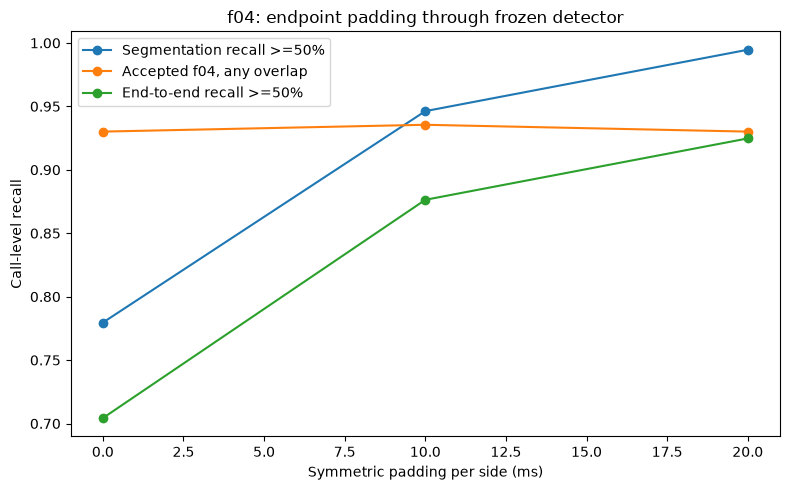

In [18]:
fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)

ax.plot(
    padding_summary[
        "padding_ms"
    ],
    padding_summary[
        "segmentation_recall_50"
    ],
    marker="o",
    label="Segmentation recall >=50%",
)

ax.plot(
    padding_summary[
        "padding_ms"
    ],
    padding_summary[
        "accepted_f04_any_overlap_recall"
    ],
    marker="o",
    label="Accepted f04, any overlap",
)

ax.plot(
    padding_summary[
        "padding_ms"
    ],
    padding_summary[
        "end_to_end_recall_50"
    ],
    marker="o",
    label="End-to-end recall >=50%",
)

ax.set(
    title="f04: endpoint padding through frozen detector",
    xlabel="Symmetric padding per side (ms)",
    ylabel="Call-level recall",
)

ax.legend()

plt.tight_layout()
plt.show()

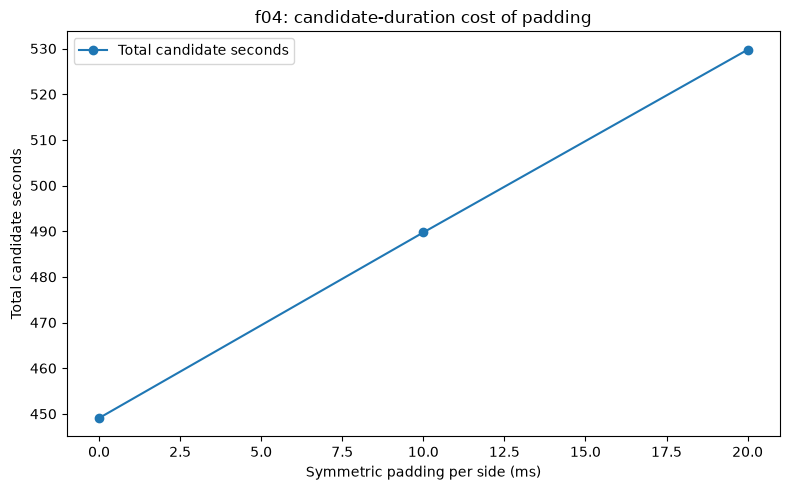

In [19]:
fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)

ax.plot(
    padding_summary[
        "padding_ms"
    ],
    padding_summary[
        "candidate_seconds"
    ],
    marker="o",
    label="Total candidate seconds",
)

ax.set(
    title="f04: candidate-duration cost of padding",
    xlabel="Symmetric padding per side (ms)",
    ylabel="Total candidate seconds",
)

ax.legend()

plt.tight_layout()
plt.show()

## 18. Decision rule for f04 padding

The notebook reports the evidence first, then computes a conservative recommendation.

Preference order:

1. maximize strict **end-to-end recovered recall at ≥50% call coverage**;
2. among ties, maximize accepted-f04 any-overlap recall;
3. among ties, choose the **smallest padding**.

This deliberately refuses to choose extra padding when it brings no downstream benefit.

The recommendation is still a Dataset-1 development result, not independent field performance.

In [20]:
best_strict = float(
    padding_summary[
        "end_to_end_recall_50"
    ].max()
)

strict_ties = (
    padding_summary[
        np.isclose(
            padding_summary[
                "end_to_end_recall_50"
            ],
            best_strict,
        )
    ]
    .copy()
)

best_any = float(
    strict_ties[
        "accepted_f04_any_overlap_recall"
    ].max()
)

final_ties = (
    strict_ties[
        np.isclose(
            strict_ties[
                "accepted_f04_any_overlap_recall"
            ],
            best_any,
        )
    ]
    .sort_values(
        "padding_ms",
        ascending=True,
    )
)

recommended = (
    final_ties.iloc[0]
)

RECOMMENDED_PADDING_MS = int(
    recommended[
        "padding_ms"
    ]
)

print(
    "Recommended f04 padding:",
    RECOMMENDED_PADDING_MS,
    "ms per side",
)

display(
    recommended.to_frame(
        "recommended_value"
    )
)

Recommended f04 padding: 20 ms per side


,recommended_value
padding_ms,20.000000
n_candidates,1907.000000
candidate_seconds,529.734104
valid_feature_fraction,1.000000
segmentation_recall_50,0.994624
accepted_f04_any_overlap_recall,0.930108
end_to_end_recall_50,0.924731
median_best_candidate_coverage,0.642857
median_best_accepted_f04_coverage,0.625000
candidate_acceptance_fraction,0.512847


## 19. Sanity checks

- No pond audio was used.
- No GMM was fitted.
- No threshold was changed.
- Only `f04` endpoint padding was varied.
- Candidate waveforms came from the original unfiltered source WAV.

In [21]:
assert set(
    candidate_decisions[
        "padding_ms"
    ].unique()
) == set(
    PADDING_MS_GRID
)

assert set(
    call_recovery[
        "padding_ms"
    ].unique()
) == set(
    PADDING_MS_GRID
)

assert (
    candidate_decisions[
        "duration_seconds"
    ] > 0
).all()

assert (
    call_recovery[
        "call_id"
    ].nunique()
    == len(
        f04_calls
    )
)

print("Padding grid complete             : OK")
print("All candidate durations positive  : OK")
print("All f04 manual calls represented  : OK")
print("Frozen GMMs used without fitting  : OK")
print("Final detector thresholds unchanged: OK")
print("Field / pond audio used           : NO")

Padding grid complete             : OK
All candidate durations positive  : OK
All f04 manual calls represented  : OK
Frozen GMMs used without fitting  : OK
Final detector thresholds unchanged: OK
Field / pond audio used           : NO


## 20. Save diagnostic outputs

This notebook does **not** update the segmentation configuration. Promotion happens only after reviewing
the executed results.

In [22]:
candidate_decisions.to_csv(
    RESULTS_DIR
    / "f04_candidate_detector_decisions.csv",
    index=False,
)

call_recovery.to_csv(
    RESULTS_DIR
    / "f04_call_end_to_end_recovery.csv",
    index=False,
)

padding_summary.to_csv(
    RESULTS_DIR
    / "f04_padding_end_to_end_summary.csv",
    index=False,
)

hypothesis_distribution.to_csv(
    RESULTS_DIR
    / "f04_hypothesis_distribution_by_padding.csv",
    index=False,
)

llr_summary.to_csv(
    RESULTS_DIR
    / "f04_target_overlap_llr_by_padding.csv",
    index=False,
)

recording_summary.to_csv(
    RESULTS_DIR
    / "f04_end_to_end_by_recording.csv",
    index=False,
)

call_wide.to_csv(
    RESULTS_DIR
    / "f04_call_padding_comparison_wide.csv",
    index=False,
)

recommendation = {
    "source_notebook":
        "08C_f04_padding_end_to_end",
    "scope":
        "Dataset 1 development diagnostic",
    "target_code":
        TARGET_CODE,
    "padding_grid_ms_per_side":
        list(
            PADDING_MS_GRID
        ),
    "recommended_padding_ms_per_side":
        RECOMMENDED_PADDING_MS,
    "selection_rule":
        (
            "maximize strict end-to-end call recovery with >=50% "
            "manual-call coverage; then accepted-f04 any-overlap recall; "
            "then smallest padding"
        ),
    "feature":
        manifest[
            "feature"
        ],
    "gmm_components":
        manifest[
            "n_components"
        ],
    "f04_threshold":
        float(
            thresholds[
                TARGET_CODE
            ]
        ),
    "gmm_retrained":
        False,
    "thresholds_changed":
        False,
    "segmentation_C_changed":
        False,
    "pond_audio_used":
        False,
    "configuration_promoted":
        False,
    "paper_status":
        (
            "endpoint padding is a project-specific extension; "
            "not reported in the paper"
        ),
}

with open(
    RESULTS_DIR
    / "f04_padding_recommendation.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        recommendation,
        f,
        indent=2,
    )

print(
    json.dumps(
        recommendation,
        indent=2,
    )
)

print()
print(
    "Saved 08C outputs to:",
    RESULTS_DIR,
)

{
  "source_notebook": "08C_f04_padding_end_to_end",
  "scope": "Dataset 1 development diagnostic",
  "target_code": "f04",
  "padding_grid_ms_per_side": [
    0,
    10,
    20
  ],
  "recommended_padding_ms_per_side": 20,
  "selection_rule": "maximize strict end-to-end call recovery with >=50% manual-call coverage; then accepted-f04 any-overlap recall; then smallest padding",
  "feature": "20_PLP_RASTA",
  "gmm_components": 4,
  "f04_threshold": 5.064719360802286,
  "gmm_retrained": false,
  "thresholds_changed": false,
  "segmentation_C_changed": false,
  "pond_audio_used": false,
  "configuration_promoted": false,
  "paper_status": "endpoint padding is a project-specific extension; not reported in the paper"
}

Saved 08C outputs to: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\candidate_call_segmentation\f04_padding_end_to_end


## 21. Interpretation after execution

Inspect these outputs first:

1. `padding_summary`
2. `llr_summary`
3. `recording_summary`
4. `call_wide`
5. `RECOMMENDED_PADDING_MS`

### Likely decisions

**If 10 ms and 20 ms give the same end-to-end recall:** choose **10 ms**.

**If 20 ms materially improves strict end-to-end recall without causing a classification/verification
drop:** choose **20 ms**.

**If padding improves geometric coverage but reduces accepted-f04 recovery:** do not promote it blindly.
That would mean the added context is hurting PLP/GMM scoring, and the endpoint problem needs a different
solution.

After this choice is reviewed, a tiny promotion step can freeze the segmentation configuration. Then,
and only then, the project is ready for the paper's final conceptual stage: field
presence/absence inference.